# 🧪 Support Vector Machines: Class Practice
**CSCI 345 · Lecture 12**

Work through this notebook **with a partner**. Run each cell with **Shift + Enter**.

- Cells marked **✏️ Exercise** have a `# TODO` for you to complete (replace each `...`).
- Cells marked **🤔 Think** ask you to write a short answer in the Markdown cell below them.

| Part | Topic |
|---|---|
| 1 | Margins and support vectors (1 feature) |
| 2 | Soft margins and the hyperparameter `C` |
| 3 | The kernel trick: adding a dimension |
| 4 | The RBF kernel and `gamma` |
| 5 | A real dataset: scaling, pipelines and `GridSearchCV` |

## 0. Setup
Run this cell first. It imports everything and defines a helper function that draws an SVM's decision boundary.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.svm import SVC
from sklearn.datasets import make_blobs, make_moons, load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.metrics.pairwise import polynomial_kernel, rbf_kernel

ORANGE, BLUE, PURPLE = "#d1620a", "#1f6feb", "#6a1b9a"


def plot_svm(model, X, y, ax=None, title="", show_margins=True, show_sv=True):
    # Draw the decision boundary (solid), margins (dashed) and support vectors (circled)
    # of a fitted SVC trained on 2 features.
    if ax is None:
        ax = plt.gca()
    x0 = np.linspace(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5, 300)
    x1 = np.linspace(X[:, 1].min() - 0.5, X[:, 1].max() + 0.5, 300)
    xx, yy = np.meshgrid(x0, x1)
    Z = model.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z > 0, levels=[-0.5, 0.5, 1.5], colors=[ORANGE, BLUE], alpha=0.12)
    ax.contour(xx, yy, Z, levels=[0], colors=[PURPLE], linewidths=2)
    if show_margins:
        ax.contour(xx, yy, Z, levels=[-1, 1], colors=[PURPLE], linewidths=1, linestyles="--")
    ax.scatter(X[y == 0, 0], X[y == 0, 1], c=ORANGE, s=30, edgecolor="white")
    ax.scatter(X[y == 1, 0], X[y == 1, 1], c=BLUE, s=30, edgecolor="white")
    if show_sv and hasattr(model, "support_vectors_"):
        sv = model.support_vectors_
        ax.scatter(sv[:, 0], sv[:, 1], s=120, facecolor="none", edgecolor="black", lw=1)
    ax.set_title(title)
    ax.set_xticks([]); ax.set_yticks([])


print("Ready! ✅")

Ready! ✅


## Part 1. Margins and Support Vectors

A doctor tried a drug at different doses (mg). `0` = **not cured**, `1` = **cured**.

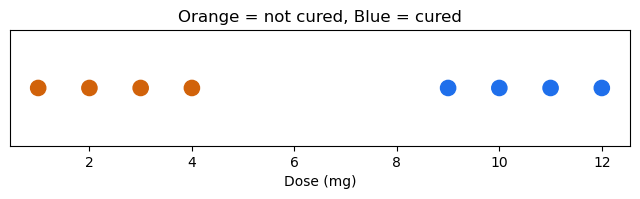

In [2]:
dose  = np.array([1, 2, 3, 4, 9, 10, 11, 12])
cured = np.array([0, 0, 0, 0, 1,  1,  1,  1])

plt.figure(figsize=(8, 1.5))
plt.scatter(dose, np.zeros_like(dose), c=[BLUE if c else ORANGE for c in cured], s=120)
plt.yticks([]); plt.xlabel("Dose (mg)"); plt.title("Orange = not cured, Blue = cured")
plt.show()

### ✏️ Exercise 1.1: find the maximal margin threshold by hand
The **maximal margin** threshold sits **halfway** between the two closest points of opposite classes.

In [9]:

closest_not_cured =  np.max(dose[cured == 0])
closest_cured     = np.min(dose[cured == 1])   

my_threshold = (closest_cured + closest_not_cured) /2       
print("My threshold:", my_threshold)

My threshold: 6.5


Now let scikit-learn find it. A **very large `C`** means "allow (almost) no mistakes", i.e. a **hard margin**.

For a linear SVM with one feature, the boundary is where $w \cdot x + b = 0$, so the threshold is $x = -b / w$.

In [10]:
X1 = dose.reshape(-1, 1)          # scikit-learn wants a 2-D array: (n_samples, n_features)
svm_1d = SVC(kernel="linear", C=1000).fit(X1, cured)

w, b = svm_1d.coef_[0][0], svm_1d.intercept_[0]
print("SVM threshold:  ", round(-b / w, 3))
print("Support vectors:", svm_1d.support_vectors_.ravel())

SVM threshold:   6.5
Support vectors: [4. 9.]


### ✏️ Exercise 1.2: predict new patients
Use `svm_1d.predict` to classify patients who received doses **5.5**, **6.4** and **8**.
Remember: `predict` needs a 2-D array.

In [11]:
new_doses = np.array([5.5, 6.4, 8]).reshape(-1, 1)
predictions = svm_1d.predict(new_doses)
print(predictions)

[0 0 1]


### 🤔 Think 1.3
Remove the patient with dose **1** and retrain. Would the threshold change? Why or why not?

*Your answer:* It would not change. The model only changes if the support vector points change.

In [12]:
# Try it! (optional)
svm_check = SVC(kernel="linear", C=1000).fit(X1[1:], cured[1:])
print("Threshold without dose 1:", round(-svm_check.intercept_[0] / svm_check.coef_[0][0], 3))

Threshold without dose 1: 6.5


## Part 2. Soft Margins and `C`

Real data overlaps, so a hard margin is impossible (or a bad idea). The hyperparameter **`C`** controls how much mistakes are punished:

- **small `C`** → mistakes are cheap → **wide** margin
- **large `C`** → mistakes are expensive → **narrow** margin

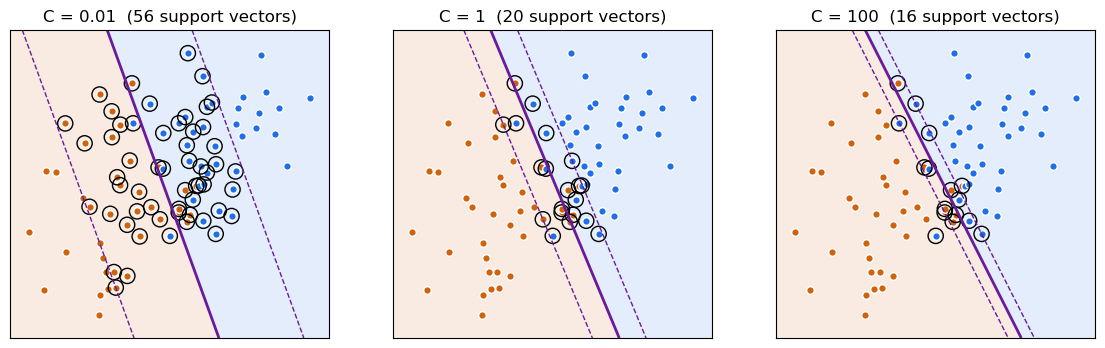

In [13]:
X2, y2 = make_blobs(n_samples=80, centers=[[-1.3, -0.6], [1.3, 0.6]], cluster_std=1.1, random_state=7)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, C in zip(axes, [0.01, 1, 100]):
    model = SVC(kernel="linear", C=C).fit(X2, y2)
    plot_svm(model, X2, y2, ax, title=f"C = {C}  ({len(model.support_)} support vectors)")
plt.show()

### ✏️ Exercise 2.1: measure the margin
For a linear SVM, the **width of the margin** (distance between the two dashed lines) is

$$\text{margin width} = \frac{2}{\lVert w \rVert}$$

Complete the loop to record the margin width, the number of support vectors and the training accuracy for each `C`.

In [ ]:
print(f"{'C':>8} | {'margin width':>12} | {'# support vectors':>17} | {'train acc':>9}")
for C in [0.001, 0.01, 0.1, 1, 10, 100]:
    model = SVC(kernel="linear", C=C).fit(X2, y2)
    w = model.coef_[0]
    width = 2/np.linalg.norm(w)       
    n_sv = len(model.support_)        
    acc = model.score(X2, y2)         
    print(f"{C:>8} | {width:>12.3f} | {n_sv:>17} | {acc:>9.3f}")

       C | margin width | # support vectors | train acc
   0.001 |       17.143 |                80 |     0.912
    0.01 |        4.069 |                56 |     0.875
     0.1 |        1.914 |                31 |     0.900
       1 |        1.254 |                20 |     0.912
      10 |        0.764 |                17 |     0.925
     100 |        0.583 |                16 |     0.925


### 🤔 Think 2.2
1. As `C` grows, what happens to the margin width and the number of support vectors?
2. Which `C` would you **expect** to be most at risk of overfitting? How would you choose `C` properly?

*Your answer:*
1. As 'C' grows, both the margin width and number of support vectors decrease.
2. I think the highest 'C', 100, is the most at risk of overfitting. I would look at how 'C' effects the number of support vectors and determine where an inreased 'C' stops having an impact.

## Part 3. The Kernel Trick

Now **only a middle dose works**: low doses are too weak, high doses cause side effects.

In [20]:
dose_s  = np.array([1, 2, 2.5, 5, 6, 7, 9, 10, 11.5])
cured_s = np.array([0, 0, 0,   1, 1, 1, 0, 0,  0])

linear_1d = SVC(kernel="linear", C=1000).fit(dose_s.reshape(-1, 1), cured_s)
print("Linear SVM accuracy on 1 feature:", linear_1d.score(dose_s.reshape(-1, 1), cured_s))

Linear SVM accuracy on 1 feature: 0.6666666666666666


A single threshold can't separate these classes, so the accuracy is poor.

### ✏️ Exercise 3.1: add a dimension by hand
Create a **2-feature** dataset with columns $x$ and $x^2$, then fit a **linear** SVM on it.

In [22]:
import pandas as pd

In [23]:
dose2 = dose_s**2
X_lifted = pd.DataFrame({
    'dose': dose_s,
    'dose_2': dose2

})   # TODO: shape (9, 2) with columns [dose, dose**2]   hint: np.c_[a, b]
lifted_svm = SVC(kernel="linear", C=1000).fit(X_lifted, cured_s)
print("Linear SVM accuracy on (x, x²):", lifted_svm.score(X_lifted, cured_s))

Linear SVM accuracy on (x, x²): 1.0


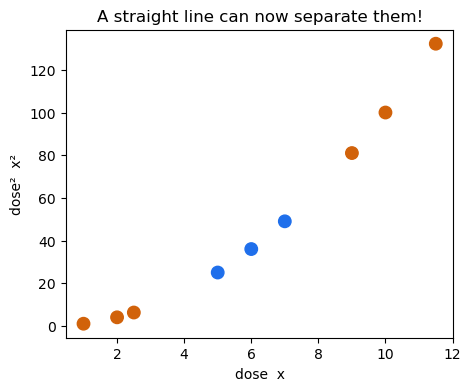

In [24]:
# Visualize the lifted data (run after Exercise 3.1)
plt.figure(figsize=(5, 4))
plt.scatter(dose_s, dose_s ** 2, c=[BLUE if c else ORANGE for c in cured_s], s=80)
plt.xlabel("dose  x"); plt.ylabel("dose²  x²"); plt.title("A straight line can now separate them!")
plt.show()

### ✏️ Exercise 3.2: let a kernel do it
In scikit-learn the polynomial kernel is $K(a, b) = (\gamma \, a b + r)^d$ with `gamma` = $\gamma$, `coef0` = $r$ and `degree` = $d$.

Fit `SVC(kernel="poly", ...)` on the **original 1-feature** data using $\gamma = 1$, $r = 0.5$, $d = 2$ (the kernel from the lecture).

In [ ]:
poly_svm = SVC(kernel="poly", C=1000, gamma=1, coef0=0.5, degree=2) 
poly_svm.fit(dose_s.reshape(-1, 1), cured_s)
print("Polynomial-kernel SVM accuracy on 1 feature:", poly_svm.score(dose_s.reshape(-1, 1), cured_s))

Polynomial-kernel SVM accuracy on 1 feature: 1.0


### ✏️ Exercise 3.3: the kernel really is a dot product
From the lecture: $(ab + \tfrac{1}{2})^2 = (a,\ a^2,\ \tfrac{1}{2}) \cdot (b,\ b^2,\ \tfrac{1}{2})$.

Complete both functions and check that they agree.

In [29]:
def poly_kernel(a, b):
    return (a*b + 1/2)**2                      # TODO: (a*b + 0.5) ** 2

def lift(x):
    return np.array([x, x**2, 1/2])          # TODO: the 3 new coordinates of x

def dot_product_version(a, b):
    return np.dot(lift(a), lift(b))

for a, b in [(2, 3), (5, 10), (1.5, -4)]:
    print(f"a={a}, b={b}:  kernel = {poly_kernel(a, b):.2f},  dot product = {dot_product_version(a, b):.2f}")

a=2, b=3:  kernel = 42.25,  dot product = 42.25
a=5, b=10:  kernel = 2550.25,  dot product = 2550.25
a=1.5, b=-4:  kernel = 30.25,  dot product = 30.25


In [ ]:
# scikit-learn's own kernel function gives the same number:
print(polynomial_kernel([[2]], [[3]], degree=2, gamma=1, coef0=0.5))   # expect 42.25

### 🤔 Think 3.4
Why is it useful that the SVM only needs the **kernel value** $K(a, b)$, and never the lifted coordinates themselves?
*(Hint: what if the lifted space had a million, or infinitely many, dimensions?)*

*Your answer:*
Computational speed. Computing a very large number of dot products would be highly time consuming.

## Part 4. The RBF Kernel and `gamma`

The RBF kernel $K(a, b) = e^{-\gamma\,\lVert a - b\rVert^2}$ measures **similarity**: close points → 1, far points → 0.

### ✏️ Exercise 4.1: compute an RBF kernel value by hand
Two points: `a = [1, 2]`, `b = [2, 4]`, and `gamma = 0.5`.

In [34]:
print(type(np.exp))


<class 'numpy.ufunc'>


In [36]:
a = np.array([1, 2])
b = np.array([2, 4])
gamma = 0.5

squared_distance = np.sum((a -b) **2)          # TODO: sum of squared differences   hint: np.sum((a - b) ** 2)
my_rbf = np.exp(squared_distance)                    # TODO: e^(-gamma * squared_distance)   hint: np.exp
print("By hand:     ", my_rbf)
print("scikit-learn:", rbf_kernel([a], [b], gamma=gamma)[0, 0])

By hand:      148.4131591025766
scikit-learn: 0.0820849986238988


Now a dataset that **no straight line** can separate:

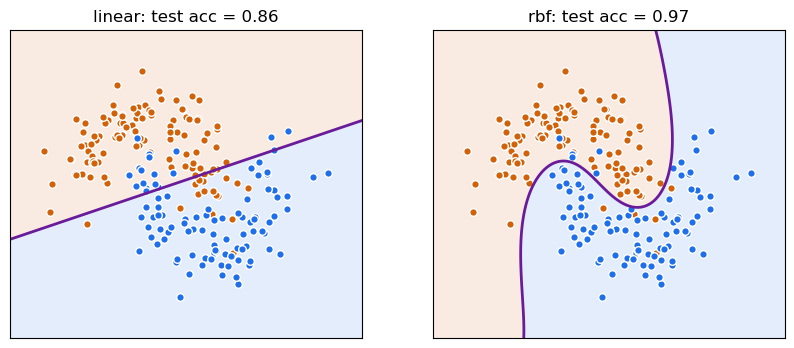

In [37]:
X_m, y_m = make_moons(n_samples=300, noise=0.25, random_state=0)
Xm_train, Xm_test, ym_train, ym_test = train_test_split(X_m, y_m, test_size=0.3, random_state=0)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, kernel in zip(axes, ["linear", "rbf"]):
    model = SVC(kernel=kernel, C=1).fit(Xm_train, ym_train)
    plot_svm(model, Xm_train, ym_train, ax, show_margins=False, show_sv=False,
             title=f"{kernel}: test acc = {model.score(Xm_test, ym_test):.2f}")
plt.show()

### ✏️ Exercise 4.2: explore `gamma`
Complete the loop: for each `gamma`, fit an RBF SVM (use `C=10`), then record the **train** and **test** accuracy.

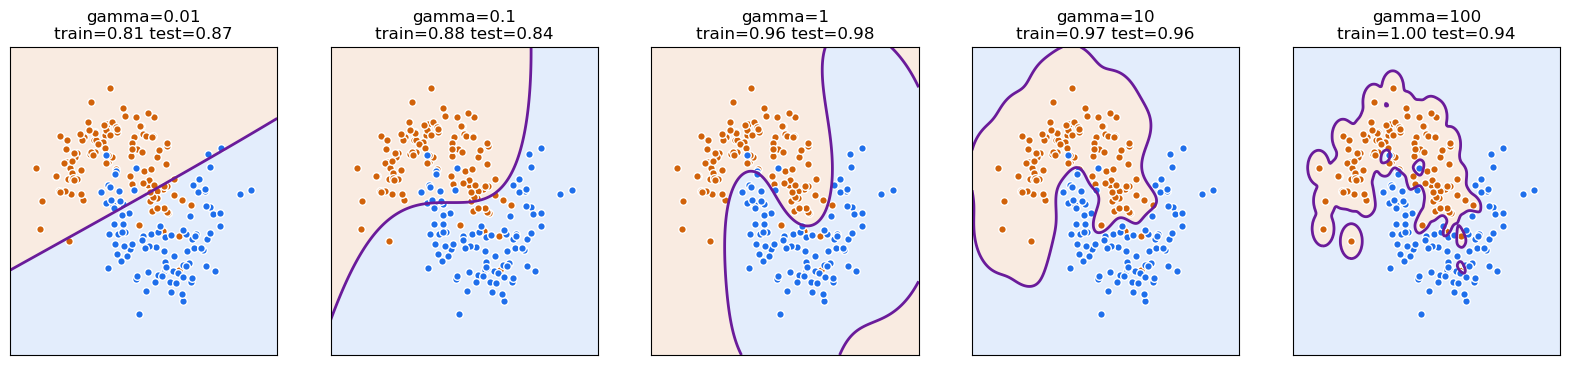

In [40]:
gammas = [0.01, 0.1, 1, 10, 100]
train_scores, test_scores = [], []

fig, axes = plt.subplots(1, len(gammas), figsize=(20, 4))
for ax, g in zip(axes, gammas):
    model = SVC(kernel = "rbf", gamma=g, C=10).fit(Xm_train,ym_train)
    train_scores.append(model.score(Xm_train,ym_train)) 
    test_scores.append(model.score(Xm_test,ym_test))                       
    plot_svm(model, Xm_train, ym_train, ax, show_margins=False, show_sv=False,
             title=f"gamma={g}\ntrain={train_scores[-1]:.2f} test={test_scores[-1]:.2f}")
plt.show()

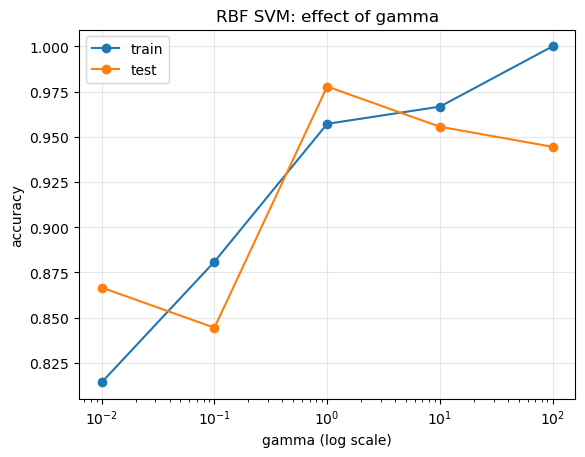

In [41]:
# Plot the scores (run after Exercise 4.2)
plt.semilogx(gammas, train_scores, "o-", label="train")
plt.semilogx(gammas, test_scores, "o-", label="test")
plt.xlabel("gamma (log scale)"); plt.ylabel("accuracy"); plt.legend(); plt.grid(alpha=0.3)
plt.title("RBF SVM: effect of gamma")
plt.show()

### 🤔 Think 4.3
1. Which `gamma` **underfits**? Which **overfits**? How can you tell from the train vs. test scores?
2. In your own words: what does `gamma` control?

*Your answer:*
Higher gammas (100) overfit while lower gammas (0.01) underfit. The test score peaks at gamma = 10^0 but decreases at both ends.
Gamma controls the amount of space each point claims.

## Part 5. A Real Dataset: Breast Cancer Diagnosis

569 tumours, 30 numeric features (radius, texture, smoothness, …). Target: `0` = malignant, `1` = benign.

In [42]:
data = load_breast_cancer()
X_bc, y_bc = data.data, data.target
X_train, X_test, y_train, y_test = train_test_split(
    X_bc, y_bc, test_size=0.25, stratify=y_bc, random_state=42)

print("Training shape:", X_train.shape)
print("Feature ranges (min → max) of the first 4 features:")
for name, col in zip(data.feature_names[:4], X_train[:, :4].T):
    print(f"  {name:<16} {col.min():8.2f} → {col.max():8.2f}")

Training shape: (426, 30)
Feature ranges (min → max) of the first 4 features:
  mean radius          6.98 →    28.11
  mean texture         9.71 →    39.28
  mean perimeter      43.79 →   188.50
  mean area          143.50 →  2499.00


The features are on **very different scales** (area is in the hundreds/thousands, smoothness is below 1).

### ✏️ Exercise 5.1: does scaling matter?
Compare the 5-fold cross-validation accuracy of an RBF SVM **without** and **with** a `StandardScaler`.
Put the scaler **inside a pipeline** so each CV fold is scaled correctly.

In [43]:
unscaled = SVC(kernel="rbf")
scaled = make_pipeline(
    StandardScaler(),
    SVC(kernel='rbf')
)  

print("Unscaled CV accuracy:", cross_val_score(unscaled, X_train, y_train, cv=5).mean().round(3))
print("Scaled   CV accuracy:", cross_val_score(scaled,   X_train, y_train, cv=5).mean().round(3))

Unscaled CV accuracy: 0.908
Scaled   CV accuracy: 0.965


### ✏️ Exercise 5.2: tune `C` and `gamma` with `GridSearchCV`
In a pipeline, the parameters of the `SVC` step are named `svc__C` and `svc__gamma` (two underscores).

In [44]:
pipe = make_pipeline(StandardScaler(), SVC(kernel="rbf"))

param_grid = {
    "svc__C":     [0.01, 0.1, 1, 10, 100],   
    "svc__gamma": [0.0001, 0.001, 0.01, 0.1, 1],    
}
search = GridSearchCV(pipe, param_grid, cv=5)
search.fit(X_train, y_train)

print("Best parameters:  ", search.best_params_)
print("Best CV accuracy: ", round(search.best_score_, 3))
print("Test accuracy:    ", round(search.score(X_test, y_test), 3))

Best parameters:   {'svc__C': 10, 'svc__gamma': 0.001}
Best CV accuracy:  0.977
Test accuracy:     0.979


### Look at the results (run after Exercise 5.2)

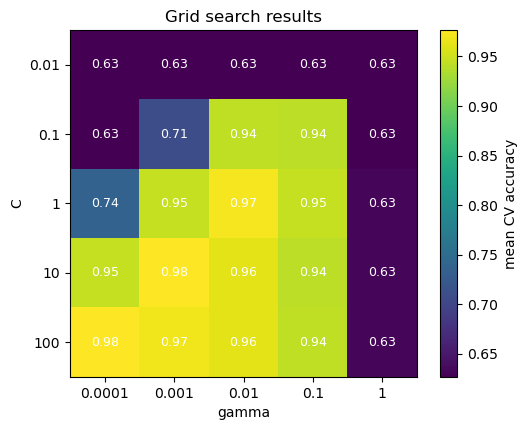

Support vectors per class: [38 40] out of 426 training points


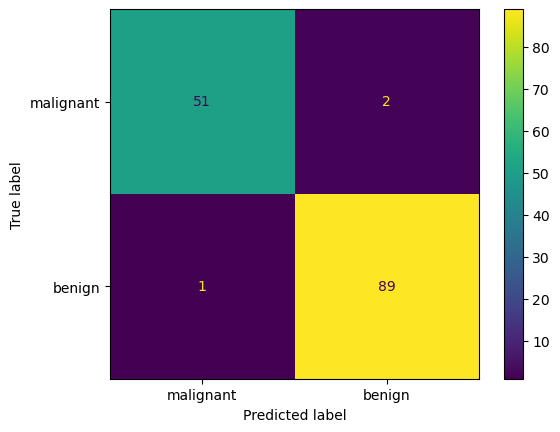

              precision    recall  f1-score   support

   malignant       0.98      0.96      0.97        53
      benign       0.98      0.99      0.98        90

    accuracy                           0.98       143
   macro avg       0.98      0.98      0.98       143
weighted avg       0.98      0.98      0.98       143



In [45]:
# A heat map of the mean CV accuracy for every (C, gamma) pair
Cs = param_grid["svc__C"]
gs = param_grid["svc__gamma"]
scores = search.cv_results_["mean_test_score"].reshape(len(Cs), len(gs))

plt.figure(figsize=(6, 4.5))
plt.imshow(scores, cmap="viridis")
plt.colorbar(label="mean CV accuracy")
plt.xticks(range(len(gs)), gs); plt.yticks(range(len(Cs)), Cs)
plt.xlabel("gamma"); plt.ylabel("C")
for i in range(len(Cs)):
    for j in range(len(gs)):
        plt.text(j, i, f"{scores[i, j]:.2f}", ha="center", va="center", color="white", fontsize=9)
plt.title("Grid search results")
plt.show()

best_svc = search.best_estimator_.named_steps["svc"]
print("Support vectors per class:", best_svc.n_support_, "out of", len(X_train), "training points")

ConfusionMatrixDisplay.from_estimator(search, X_test, y_test, display_labels=data.target_names)
plt.show()
print(classification_report(y_test, search.predict(X_test), target_names=data.target_names))

### 🤔 Think 5.3
1. How many of the training points ended up as **support vectors**? What does that tell you about how "hard" the problem is?
2. In a cancer diagnosis, which mistake is worse: a **false negative** (malignant predicted as benign) or a **false positive**? What would you change to reduce the worse one? *(Hint: Lecture 4 on precision and recall.)*

*Your answer:*
1. 38 of the points ended up as support vectors. That tells me that we are in a really high dimension because the data is highly clustered.
2. I would say that a false negative is worse. I would change the decision boundary so that the recall was higher.

## ⭐ Challenge (optional)
Which **kernel** works best on the breast cancer data? Use `GridSearchCV` with a grid that includes **different kernels**.

Hint: a grid can be a **list of dictionaries**, one per kernel, e.g.
```python
param_grid = [
    {"svc__kernel": ["linear"], "svc__C": [...]},
    {"svc__kernel": ["rbf"],    "svc__C": [...], "svc__gamma": [...]},
    {"svc__kernel": ["poly"],   "svc__C": [...], "svc__degree": [2, 3]},
]
```

In [50]:
pipe = make_pipeline(
    StandardScaler(),
    SVC()
)

param_grid = {
    "svc__kernel" : ["linear", "rbf", "poly"],
    "svc__C":     [0.01, 0.1, 1, 10, 100],   
    "svc__gamma": [0.0001, 0.001, 0.01, 0.1, 1],    
}
search = GridSearchCV(pipe, param_grid, cv=5)
search.fit(X_train, y_train)

print("Best parameters:  ", search.best_params_)
print("Best CV accuracy: ", round(search.best_score_, 3))
print("Test accuracy:    ", round(search.score(X_test, y_test), 3))

Best parameters:   {'svc__C': 0.01, 'svc__gamma': 0.0001, 'svc__kernel': 'linear'}
Best CV accuracy:  0.977
Test accuracy:     0.958


## ✅ Summary
- **Support vectors** are the points closest to the boundary; they alone define it.
- **`C`** trades margin width for training mistakes (small `C` → wide, soft margin).
- **Kernels** let a linear classifier work in a higher-dimensional space **without computing it**.
- **`gamma`** (RBF) controls how far each point's influence reaches (large `gamma` → wiggly, overfitting).
- Always **scale** your features (in a **pipeline**) and **tune** `C` / `gamma` with **cross-validation**.